
# Машинный перевод Transformer
В этом ноутбуке попробуем решить задачу машинного перевода с русского на английский язык.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data="/content/drive/MyDrive/Colab Notebooks/data2/FinalTranslationdataset.csv"

In [ ]:
!pip install transformers sentencepiece sacrebleu -q

import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from transformers import MarianTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

df = pd.read_csv(data)

print("Колонки:", df.columns.tolist())
print("Размер:", len(df))
df = df.reset_index(drop=True)

SRC_COL = "Nepali"
TGT_COL = "English"

Колонки: ['English', 'Nepali']
Размер: 150000


In [ ]:
df.head()

,English,Nepali
0,"It happened after the death of Saul, when Davi...",दाऊदले अमालेकीहरूलाई हराएर पछि सिकलग गए। यो शा...
1,"it happened on the third day, that behold, a m...",तब तेस्रो दिनमा एउटा जवान सैनिक सिकलगमा आयो। त...
2,"David said to him, ""Where do you come from?"" H...","दाऊदले त्यसलाई सोधे, “तिमी कहाँबाट आयौ?” त्यस ..."
3,"David said to him, ""How did it go? Please tell...","दाऊदले भने, “मलाई भन, के भयो?” त्यसले भन्यो, “..."
4,"David said to the young man who told him, ""How...","दाऊदले त्यस सैनिकलाई भने, “तिमीले कसरी जान्यौ ..."


Узнаем сколько у нас предложений.

In [ ]:
df.shape

(150000, 2)

Делим выборку на обучающую и тестовую.

In [ ]:
!pip install transformers datasets sacrebleu sentencepiece accelerate -q

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import MarianTokenizer, AutoModelForSeq2SeqLM
from datasets import load_dataset
import numpy as np

model_checkpoint = "Helsinki-NLP/opus-mt-mul-en"
tokenizer = MarianTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"Vocab size: {tokenizer.vocab_size}")
print(f"Pad token: {tokenizer.pad_token} (id={tokenizer.pad_token_id})")
print(f"EOS token: {tokenizer.eos_token} (id={tokenizer.eos_token_id})")

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Vocab size: 64172
Pad token: <pad> (id=64171)
EOS token: </s> (id=0)


In [ ]:
def tokenize_manually(text, max_length=64):
    tokens = tokenizer.tokenize(str(text))[:max_length - 1]
    ids = tokenizer.convert_tokens_to_ids(tokens)
    ids = ids + [tokenizer.eos_token_id]
    return ids

In [ ]:
class TranslationDataset(Dataset):
    def __init__(self, dataframe, src_col, tgt_col, max_length=128):
        self.df = dataframe.reset_index(drop=True)
        self.src_col = src_col
        self.tgt_col = tgt_col
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        src_text = self.df.iloc[idx][self.src_col]
        tgt_text = self.df.iloc[idx][self.tgt_col]
        return str(src_text), str(tgt_text)

In [ ]:
def collate_fn_manual(batch, max_length=200):
    src_texts, tgt_texts = zip(*batch)

    src_ids_list = [tokenize_manually(t, max_length) for t in src_texts]
    tgt_ids_list = [tokenize_manually(t, max_length) for t in tgt_texts]

    pad_id = tokenizer.pad_token_id


    max_src_len = max(len(ids) for ids in src_ids_list)
    input_ids, attention_mask = [], []
    for ids in src_ids_list:
        pad_len = max_src_len - len(ids)
        input_ids.append(ids + [pad_id] * pad_len)
        attention_mask.append([1] * len(ids) + [0] * pad_len)


    max_tgt_len = max(len(ids) for ids in tgt_ids_list)
    labels = []
    for ids in tgt_ids_list:
        pad_len = max_tgt_len - len(ids)
        labels.append(ids + [-100] * pad_len)

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
    }

In [ ]:
from sklearn.model_selection import train_test_split


train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, shuffle=True)
train_df = train_df.sample(n=min(5000, len(train_df)), random_state=42).reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

In [ ]:
val_df = val_df.sample(n=min(2000, len(val_df)), random_state=42).reset_index(drop=True)

In [ ]:
train_dataset = TranslationDataset(train_df, SRC_COL, TGT_COL)
val_dataset = TranslationDataset(val_df, SRC_COL, TGT_COL)

In [ ]:
batch_size = 16
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn_manual
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn_manual
)


In [ ]:
num_epochs = 10
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.05),
    num_training_steps=total_steps
)

In [ ]:
model.train()
global_step = 0


for epoch in range(num_epochs):
    total_loss = 0
    for batch_idx, batch in enumerate(train_loader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        global_step += 1

        if global_step % 1000 == 0:
            print(f"Epoch {epoch+1} | Step {global_step} | Loss: {loss.item():.4f}")

    avg_train_loss = total_loss / len(train_loader)


    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            val_loss += outputs.loss.item()
    avg_val_loss = val_loss / len(val_loader)
    model.train()

    print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, val_loss={avg_val_loss:.4f}")

Epoch 1: train_loss=1.4518, val_loss=2.1771
Epoch 2: train_loss=1.3994, val_loss=2.1481
Epoch 3: train_loss=1.3117, val_loss=2.1586
Epoch 4 | Step 1000 | Loss: 1.1957
Epoch 4: train_loss=1.2383, val_loss=2.1483
Epoch 5: train_loss=1.1748, val_loss=2.1426
Epoch 6: train_loss=1.1233, val_loss=2.1569
Epoch 7 | Step 2000 | Loss: 1.1792
Epoch 7: train_loss=1.0800, val_loss=2.1546
Epoch 8: train_loss=1.0489, val_loss=2.1499
Epoch 9: train_loss=1.0216, val_loss=2.1513
Epoch 10 | Step 3000 | Loss: 1.0025
Epoch 10: train_loss=1.0067, val_loss=2.1561


In [ ]:
def translate(text, max_length=128, num_beams=4):
    model.eval()
    with torch.no_grad():
        ids = tokenize_manually(text, max_length)
        input_ids = torch.tensor([ids], dtype=torch.long).to(device)
        attention_mask = torch.ones_like(input_ids)

        generated = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_length=max_length,
            num_beams=num_beams,
            early_stopping=True
        )
        return tokenizer.decode(generated[0], skip_special_tokens=True)

In [ ]:
for i in range(3):
    src, tgt = val_dataset[i]
    pred = translate(src)
    print(f"SRC: {src}")
    print(f"REF: {tgt}")
    print(f"PRED: {pred}")

SRC: तालिकाको पहिलो स्तम्भ जस्तै स्तम्भ थप्नुहोस्
REF: Add the column as the first column of the table
PRED: Add a column as the first column of the table
SRC: समर्थ हामी पनि परमेश्वरको विश्राममा प्रवेश गर्ने सक्दो कोशिश गरौं हामीले सक्दो कोशिश गर्नुपर्छ ता कि परमेश्वरको आज्ञा नमान्नेहरूको नमूना बनेर हामी नष्ट नहौं।
REF: Let us therefore give diligence to enter into that rest, lest anyone fall after the same example of disobedience.
PRED: For even we everyone into God's house, we must work the things, that we may not be destroyed for the order of the people who are at righteous.
SRC: “” कागजात लोड गर्न असफल भयो
REF: Loading document from “”
PRED: Failed to load the document “”


In [ ]:
!pip install sacrebleu evaluate -q

In [ ]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import evaluate
import sacrebleu
import matplotlib.pyplot as plt


src_texts = val_df[SRC_COL].astype(str).tolist()
ref_texts = val_df[TGT_COL].astype(str).tolist()

predictions = []
for text in tqdm(src_texts, desc="Translating"):
    try:
        pred = translate(text, max_length=128, num_beams=4)
    except Exception as e:
        pred = ""
    predictions.append(pred)

print(f"Готово: {len(predictions)} переводов")

Translating:   0%|          | 0/2000 [00:00<?, ?it/s]

Готово: 2000 переводов


In [ ]:
bleu_metric = evaluate.load("sacrebleu")
chrf_metric = evaluate.load("chrf")

refs_wrapped = [[r] for r in ref_texts]

bleu_score = bleu_metric.compute(predictions=predictions, references=refs_wrapped)
chrf_score = chrf_metric.compute(predictions=predictions, references=refs_wrapped)


print(f"BLEU:  {bleu_score['score']:.2f}")
print(f"chrF:  {chrf_score['score']:.2f}")

BLEU:  19.03
chrF:  43.23


In [ ]:

for i in range(min(10, len(predictions))):
    print(f"\n[{i+1}]")
    print(f"  SRC:  {src_texts[i]}")
    print(f"  REF:  {ref_texts[i]}")
    print(f"  PRED: {predictions[i]}")





[1]
  SRC:  तालिकाको पहिलो स्तम्भ जस्तै स्तम्भ थप्नुहोस्
  REF:  Add the column as the first column of the table
  PRED: Add a column as the first column of the table

[2]
  SRC:  समर्थ हामी पनि परमेश्वरको विश्राममा प्रवेश गर्ने सक्दो कोशिश गरौं हामीले सक्दो कोशिश गर्नुपर्छ ता कि परमेश्वरको आज्ञा नमान्नेहरूको नमूना बनेर हामी नष्ट नहौं।
  REF:  Let us therefore give diligence to enter into that rest, lest anyone fall after the same example of disobedience.
  PRED: For even we everyone into God's house, we must work the things, that we may not be destroyed for the order of the people who are at righteous.

[3]
  SRC:  “” कागजात लोड गर्न असफल भयो
  REF:  Loading document from “”
  PRED: Failed to load the document “”

[4]
  SRC:  १८. दस्तुरः मतदातालाई पहिलो पटक निःशुल्क मतदाता परिचयपत्र उपलब्ध गराइनेछ तर नियम १२ बमोजिम प्रतिलिपि जनाई अर्को मतदाता परिचयपत्र लिंदा आयोगले तोके बमोजिम दस्तुर लाग्नेछ । १९.
  REF:  Fee: Voters Identity Card shall be provided on free of charge for the first tim

In [ ]:
print(model)

MarianMTModel(
  (model): MarianModel(
    (shared): Embedding(64172, 512, padding_idx=64171)
    (encoder): MarianEncoder(
      (embed_tokens): Embedding(64172, 512, padding_idx=64171)
      (embed_positions): MarianSinusoidalPositionalEmbedding(512, 512)
      (layers): ModuleList(
        (0-5): 6 x MarianEncoderLayer(
          (self_attn): MarianAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation_fn): SiLU()
          (fc1): Linear(in_features=512, out_features=2048, bias=True)
          (fc2): Linear(in_features=2048, out_features=512, bias=True)
          (final_layer_norm): LayerNorm((512,), eps=1e-05

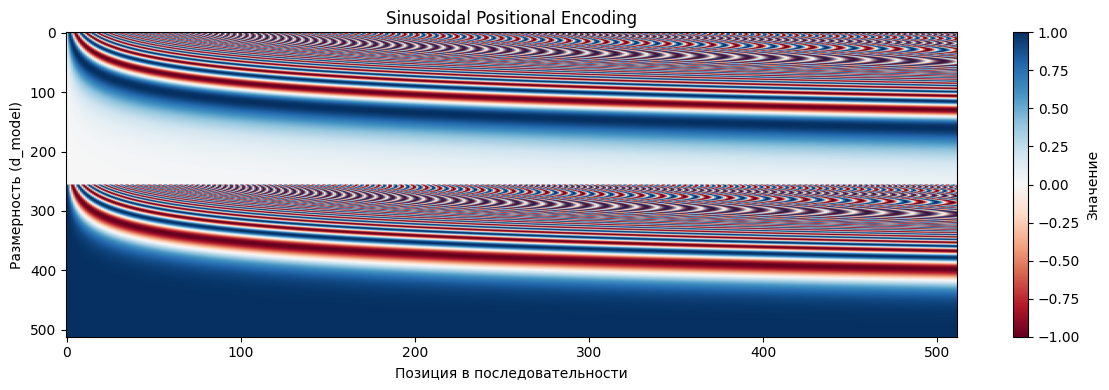

In [ ]:
import matplotlib.pyplot as plt

pe = model.model.encoder.embed_positions.weight.detach().cpu().numpy()

plt.figure(figsize=(12, 4))
plt.imshow(pe.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("Позиция в последовательности")
plt.ylabel("Размерность (d_model)")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar(label="Значение")
plt.tight_layout()
plt.show()